In [38]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import copy
import math
x = np.array([ 850, 920, 1100, 1250, 1300, 1450, 1500, 1600, 1750, 1800,
    1900, 2050, 2150, 2200, 2350, 2400, 2550, 2600, 2750, 2900,
    3000, 3100, 3250, 3300, 3450, 3500, 3650, 3800, 3900, 4000.49,4544])##size in sq meters
print(x)
print (len(x))
y = np.array([1800, 1700, 2200, 2100, 2600, 2450, 2900, 2750, 3100, 3300,
    3000, 3600, 3400, 3900, 3750, 4200, 4100, 4400, 4300, 4700,
    5100, 4900, 5300, 5600, 5400, 5900, 5700, 6200, 6100, 6600,6880])###price in thousands of dollars
print(y)
print(len(x))


[ 850.    920.   1100.   1250.   1300.   1450.   1500.   1600.   1750.
 1800.   1900.   2050.   2150.   2200.   2350.   2400.   2550.   2600.
 2750.   2900.   3000.   3100.   3250.   3300.   3450.   3500.   3650.
 3800.   3900.   4000.49 4544.  ]
31
[1800 1700 2200 2100 2600 2450 2900 2750 3100 3300 3000 3600 3400 3900
 3750 4200 4100 4400 4300 4700 5100 4900 5300 5600 5400 5900 5700 6200
 6100 6600 6880]
31


In [39]:
x_train=x
y_train=y
print("Type of x_train:",type(x_train))
print("First five elements of x_train are:\n", x_train[:5]) 
print("Type of y_train:",type(y_train))
print("First five elements of y_train are:\n", y_train[:5])  

Type of x_train: <class 'numpy.ndarray'>
First five elements of x_train are:
 [ 850.  920. 1100. 1250. 1300.]
Type of y_train: <class 'numpy.ndarray'>
First five elements of y_train are:
 [1800 1700 2200 2100 2600]


In [40]:
print ('The shape of x_train is:', x_train.shape)
print ('The shape of y_train is: ', y_train.shape)
print ('Number of training examples (m):', len(x_train))
##training examples

The shape of x_train is: (31,)
The shape of y_train is:  (31,)
Number of training examples (m): 31


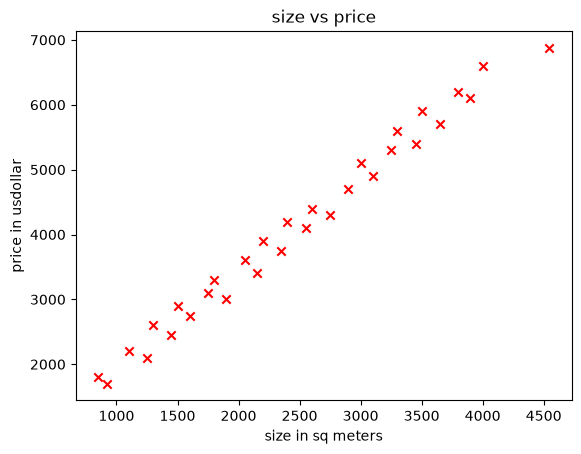

In [62]:
plt.scatter(x_train, y_train, marker='x', c='r') 
plt.title("size vs price")
####y axis label
plt.ylabel('price in usdollar')
### x axis label
plt.xlabel('size in sq meters')
plt.show()

Cost function


In [63]:
def compute_cost(x, y, w, b): 
    #number of training examples
    m = x.shape[0] 
    total_cost = 0
    for i in range(m):
        f_wb = w * x[i] + b
        cost = (f_wb - y[i]) ** 2
        total_cost += cost
    total_cost = total_cost / (2 * m)
    return total_cost

In [47]:
initial_w = 1500
initial_b = 500
cost = compute_cost(x_train, y_train, initial_w, initial_b)
print(type(cost))
print(f'Cost at initial w: {cost:.3f}')


<class 'numpy.float64'>
Cost at initial w: 8000109072663.307


Gradient descent

In [48]:
def compute_gradient(x, y, w, b): 
    m = x.shape[0]
    dj_dw = 0
    dj_db = 0
    for i in range(m):
        f_wb = w * x[i] + b
        error = f_wb - y[i]
        dj_db += error
        dj_dw += error * x[i]

    dj_dw = dj_dw / m
    dj_db = dj_db / m
    return dj_dw, dj_db

In [65]:
def gradient_descent(x, y, w_in, b_in, alpha, num_iters):
    w = w_in
    b = b_in
    for i in range(num_iters):

        dj_dw, dj_db = compute_gradient(x, y, w, b)

        w = w - alpha * dj_dw
        b = b - alpha * dj_db

    return w, b

In [66]:
###gradient with w initialized to zeroes
initial_w = 0
initial_b = 0
tmp_dj_dw, tmp_dj_db = compute_gradient(x_train, y_train, initial_w, initial_b)
print('Gradient at initial w, b (zeros):', tmp_dj_dw, tmp_dj_db)

Gradient at initial w, b (zeros): -11667579.161290323 -4126.774193548387


In [71]:
###gradient with non-zero w
test_w = 0.2
test_b = 0.2
tmp_dj_dw, tmp_dj_db = compute_gradient(x_train, y_train, test_w, test_b)
print('Gradient at test w, b:', tmp_dj_dw, tmp_dj_db)
w_final, b_final = gradient_descent(
    x_train,
    y_train,
    w_in=0,
    b_in=0,
    alpha=0.00000001,
    num_iters=1000
)
print("Final w:", w_final)
print("Final b:", b_final)

Gradient at test w, b: -10242062.253354194 -3630.6742580645177
Final w: 1.637530402246238
Final b: 0.0012350211968624161


In [75]:
initial_cost = compute_cost(x_train, y_train, 0, 0)
final_cost = compute_cost(x_train, y_train, w_final, b_final)
print("Initial cost:", initial_cost)
print("Final cost:", final_cost)

Initial cost: 9585030.64516129
Final cost: 32020.276098224025


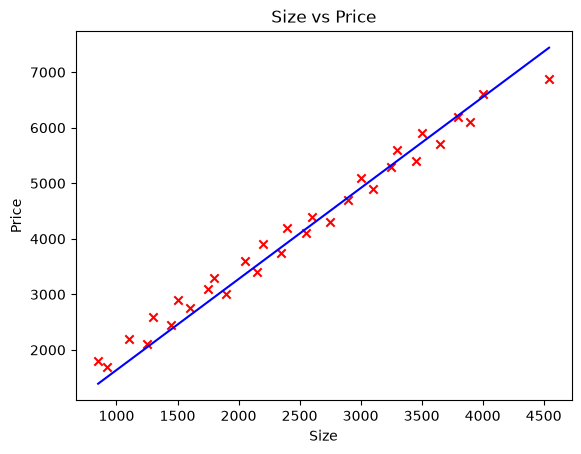

In [78]:
predicted = w_final * x_train + b_final
plt.scatter(x_train, y_train, marker='x', c='r')
plt.plot(x_train, predicted, c='b')
plt.title("Size vs Price")
plt.ylabel("Price")
plt.xlabel("Size")
plt.show()